In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [85]:
df_original = pd.read_csv('train.csv')
df1_original = pd.read_csv('test.csv')

df = pd.read_csv('train.csv')
df
df1 = pd.read_csv('test.csv')
df1


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [87]:
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


In [88]:
df.shape
df1.shape

(418, 11)

In [89]:
df.head()
df1.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [90]:
df.describe()
df1.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


In [91]:
df.columns
df1.columns
print(df.isnull().sum())
print(df1.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [92]:
print(df.duplicated().sum())
print(df1.duplicated().sum())

0
0


In [93]:

print(df.nunique())
print(df1.nunique())

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64
PassengerId    418
Pclass           3
Name           418
Sex              2
Age             79
SibSp            7
Parch            8
Ticket         363
Fare           169
Cabin           76
Embarked         3
dtype: int64


In [94]:
# Check target distribution
print(df['Survived'].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [95]:
# Exploratory Data Analysis (EDA)

# survived by gender and rate
print(df.groupby('Sex')['Survived'].value_counts())
print(df.groupby('Sex')['Survived'].mean()*100)
print(df1['Sex'].value_counts())
print(df1['Sex'].value_counts(normalize=True) * 100)




Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64
Sex
male      266
female    152
Name: count, dtype: int64
Sex
male      63.636364
female    36.363636
Name: proportion, dtype: float64


In [96]:
# Survival by passenger class
print(df.groupby('Pclass')['Survived'].value_counts())
print(df.groupby('Pclass')['Survived'].mean() * 100)
# Survival by passenger class
print(df1.groupby('Pclass').value_counts())
print(df1['Pclass'].value_counts())

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: count, dtype: int64
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
Pclass  PassengerId  Name                                                     Sex     Age   SibSp  Parch  Ticket         Fare      Cabin            Embarked
1       904          Snyder, Mrs. John Pillsbury (Nelle Stevenson)            female  23.0  1      0      21228          82.2667   B45              S           1
        906          Chaffee, Mrs. Herbert Fuller (Carrie Constance Toogood)  female  47.0  1      0      W.E.P. 5734    61.1750   E31              S           1
        916          Ryerson, Mrs. Arthur Larned (Emily Maria Borie)          female  48.0  1      3      PC 17608       262.3750  B57 B59 B63 B66  C           1
        918          Ostby, Miss. Helene Ragnhild                             female  2

In [97]:
# Survival by age
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 80])

print(df.groupby('AgeGroup', observed=True)['Survived'].mean() * 100)

AgeGroup
(0, 12]     57.971014
(12, 18]    42.857143
(18, 35]    38.268156
(35, 60]    40.000000
(60, 80]    22.727273
Name: Survived, dtype: float64


In [98]:
# Survival by family size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

print(df.groupby('FamilySize')['Survived'].mean() * 100)
df1['FamilySize'] = df1['SibSp'] + df1['Parch'] + 1

print(df1['FamilySize'].value_counts().sort_index())

FamilySize
1     30.353818
2     55.279503
3     57.843137
4     72.413793
5     20.000000
6     13.636364
7     33.333333
8      0.000000
11     0.000000
Name: Survived, dtype: float64
FamilySize
1     253
2      74
3      57
4      14
5       7
6       3
7       4
8       2
11      4
Name: count, dtype: int64


In [99]:

# Survival by ticket fare
print(df.groupby('Fare')['Survived'].value_counts())
print(df.groupby('Fare')['Survived'].mean() * 100)
df['FareGroup'] = pd.cut(df['Fare'], bins=5)

print(df.groupby('FareGroup', observed=True)['Survived'].mean() * 100)

Fare      Survived
0.0000    0           14
          1            1
4.0125    0            1
5.0000    0            1
6.2375    0            1
                      ..
247.5208  0            1
262.3750  1            2
263.0000  1            2
          0            2
512.3292  1            3
Name: count, Length: 330, dtype: int64
Fare
0.0000        6.666667
4.0125        0.000000
5.0000        0.000000
6.2375        0.000000
6.4375        0.000000
               ...    
227.5250     75.000000
247.5208     50.000000
262.3750    100.000000
263.0000     50.000000
512.3292    100.000000
Name: Survived, Length: 248, dtype: float64
FareGroup
(-0.512, 102.466]      36.157518
(102.466, 204.932]     75.757576
(204.932, 307.398]     64.705882
(409.863, 512.329]    100.000000
Name: Survived, dtype: float64


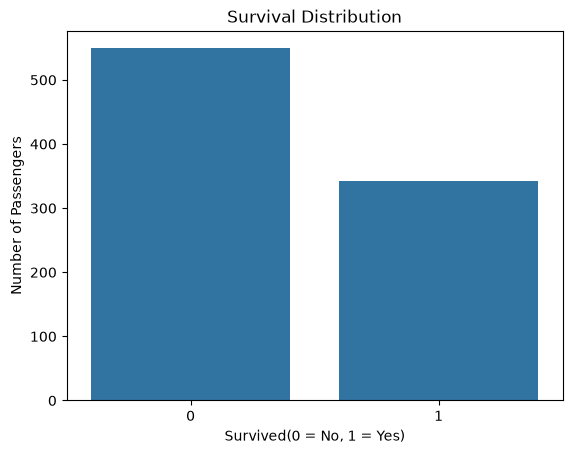

In [100]:
# Visualization of the data
# distribution(using count plot)

sns.countplot(x='Survived', data=df)
plt.title('Survival Distribution')
plt.xlabel('Survived(0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.show()


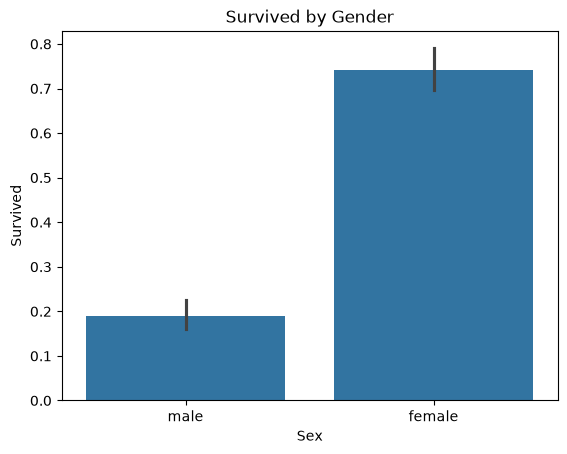

In [101]:
# survived by gender
sns.barplot(data=df,  x='Sex', y='Survived')
plt.title('Survived by Gender')
plt.show()

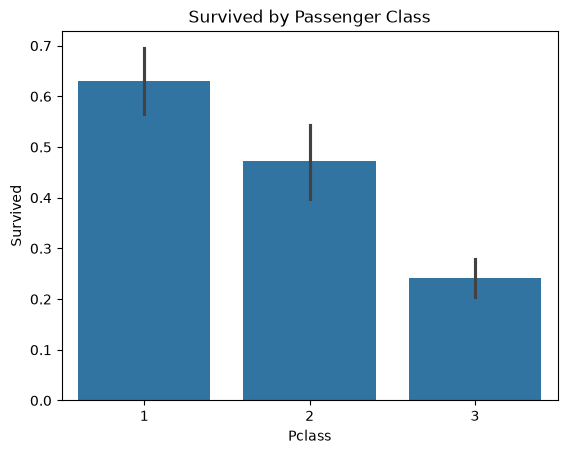

In [102]:
# passenger class
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Survived by Passenger Class')
plt.show()

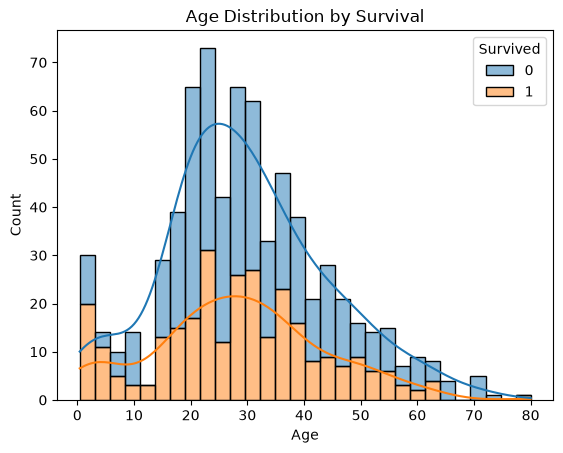

In [103]:
# Survival vs Age
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, multiple='stack')
plt.title('Age Distribution by Survival')
plt.show()

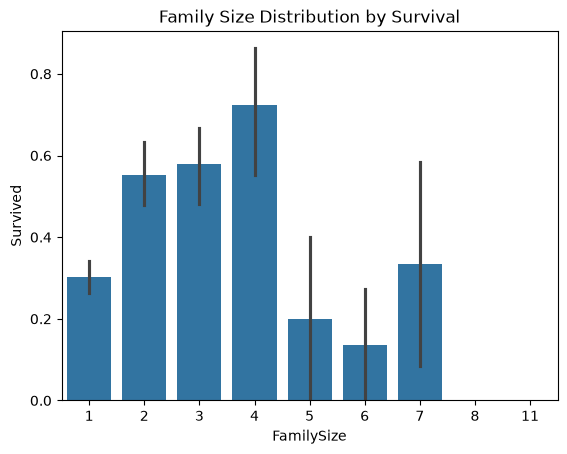

In [104]:
# survival by family size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

sns.barplot(data=df, x='FamilySize', y='Survived')
plt.title('Family Size Distribution by Survival')
plt.show()

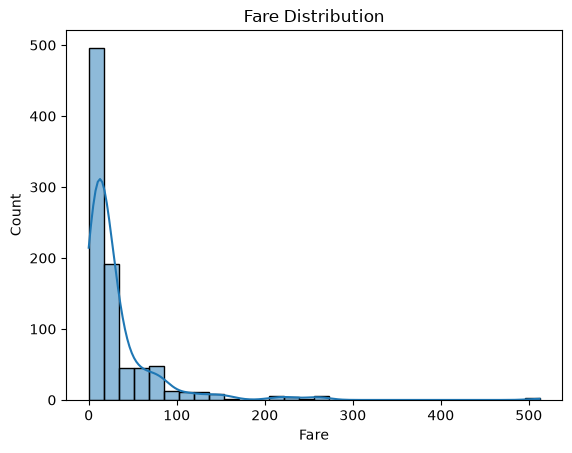

In [105]:
# Fare distribution by survival
sns.histplot(data=df, x='Fare', bins=30, kde=True)
plt.title('Fare Distribution')
plt.show()

In [106]:

# Data proprocessing

In [107]:
# Missing value hanldling

# Age
age_median = df['Age'].median()
df['Age'] = df['Age'].fillna(age_median)
df1['Age'] = df1['Age'].fillna(age_median)

# Embarked
embarked_mode = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(embarked_mode)
df1['Embarked'] = df1['Embarked'].fillna(embarked_mode)

# Fare
df1['Fare'] = df1['Fare'].fillna(df['Fare'].median())
# drop unnessary column
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin', 'FareGroup'], axis=1, inplace=True)

df1.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

In [108]:
# Categorical Encoding
df = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

df1 = pd.get_dummies(
    df1,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print(df.head())
print(df1.head())

print(df.dtypes)

   Survived  Pclass   Age  SibSp  Parch     Fare  AgeGroup  FamilySize  \
0         0       3  22.0      1      0   7.2500  (18, 35]           2   
1         1       1  38.0      1      0  71.2833  (35, 60]           2   
2         1       3  26.0      0      0   7.9250  (18, 35]           1   
3         1       1  35.0      1      0  53.1000  (18, 35]           2   
4         0       3  35.0      0      0   8.0500  (18, 35]           1   

   Sex_male  Embarked_Q  Embarked_S  
0         1           0           1  
1         0           0           0  
2         0           0           1  
3         0           0           1  
4         1           0           1  
   Pclass   Age  SibSp  Parch     Fare  FamilySize  Sex_male  Embarked_Q  \
0       3  34.5      0      0   7.8292           1         1           1   
1       3  47.0      1      0   7.0000           2         0           0   
2       2  62.0      0      0   9.6875           1         1           1   
3       3  27.0      0 

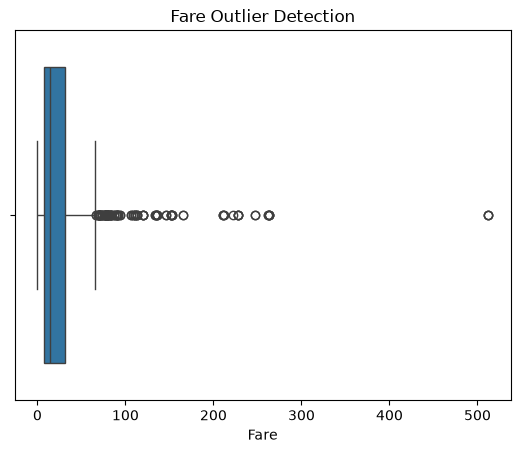

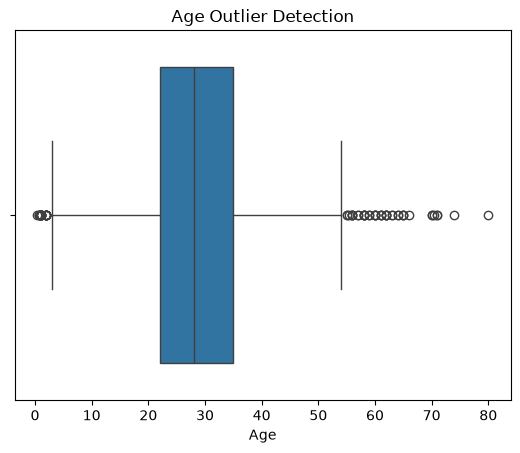

In [109]:

# outlier Checking
sns.boxplot(data=df, x='Fare')
plt.title('Fare Outlier Detection')
plt.show()

sns.boxplot(data=df, x='Age')
plt.title('Age Outlier Detection')
plt.show()

In [110]:
# Feature Engineering

In [111]:
# isAlone
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df1['IsAlone'] = (df1['FamilySize'] == 1).astype(int)

In [112]:
# Title

# Title Extraction

df['Title'] = df_original['Name'].str.extract(
    r' ([A-Za-z]+)\.', expand=False
)

df1['Title'] = df1_original['Name'].str.extract(
    r' ([A-Za-z]+)\.', expand=False
)

In [113]:
# Group Rare Titles

rare_titles = [
    'Dr', 'Rev', 'Col', 'Major', 'Mlle',
    'Countess', 'Capt', 'Ms', 'Sir', 'Lady',
    'Jonkheer', 'Don', 'Dona'
]

df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df1['Title'] = df1['Title'].replace(rare_titles, 'Rare')


In [114]:
# Check Results

print(df['Title'].value_counts())
print(df1['Title'].value_counts())

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       26
Mme         1
Name: count, dtype: int64
Title
Mr        240
Miss       78
Mrs        72
Master     21
Rare        7
Name: count, dtype: int64


In [115]:
# Age_Group
bins = [0, 12, 18, 35, 60, 100]
labels = ['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']

df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels)
df1['AgeGroup'] = pd.cut(df1['Age'], bins=bins, labels=labels)

In [116]:
# Encoding Title and AgeGroup
df = pd.get_dummies(
    df, columns=['Title', 'AgeGroup'], drop_first=True, dtype=int)
df1 = pd.get_dummies(
    df1, columns=['Title', 'AgeGroup'], drop_first=True, dtype=int)

df1 = df1.reindex(columns=df.drop('Survived', axis=1).columns, fill_value=0)

In [117]:

# Model Building
# LogisticRegression

X = df.drop('Survived', axis=1)
y = df['Survived']

# Train-Validation Split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check Shape

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print(X_train.dtypes)                        
print(list(df1.columns) == list(X.columns))  

X_train: (712, 19)
X_val: (179, 19)
y_train: (712,)
y_val: (179,)
Pclass                    int64
Age                     float64
SibSp                     int64
Parch                     int64
Fare                    float64
FamilySize                int64
Sex_male                  int64
Embarked_Q                int64
Embarked_S                int64
IsAlone                   int64
Title_Miss                int64
Title_Mme                 int64
Title_Mr                  int64
Title_Mrs                 int64
Title_Rare                int64
AgeGroup_Teenager         int64
AgeGroup_Young Adult      int64
AgeGroup_Adult            int64
AgeGroup_Senior           int64
dtype: object
True


Train Accuracy: 0.9831460674157303
Validation Accuracy: 0.8156424581005587
              precision    recall  f1-score   support

           0       0.85      0.85      0.85       110
           1       0.76      0.77      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



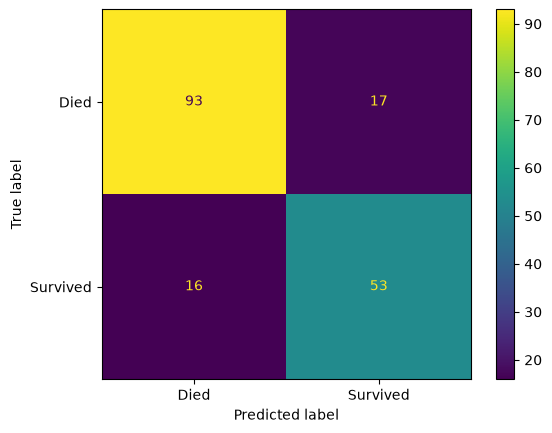

In [118]:
# Decision Tree
from sklearn.model_selection import train_test_split

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_val)

print("Train Accuracy:", accuracy_score(y_train, dt.predict(X_train)))
print("Validation Accuracy:", accuracy_score(y_val, y_pred))
print(classification_report(y_val, y_pred))

cm = confusion_matrix(y_val, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived']).plot()
plt.show()

In [119]:

# Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train Model
rf_model.fit(X_train, y_train)

# Validation Prediction
y_pred_rf = rf_model.predict(X_val)

# Calculate Accuracy
rf_accuracy = accuracy_score(y_val, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")


Random Forest Accuracy: 81.56424581005587 %


In [120]:

# Train Random Forest on Full Training Data

X = df.drop('Survived', axis=1)
y = df['Survived']

rf_model.fit(X, y)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

In [121]:

# Predict Test Dataset

test_predictions = rf_model.predict(df1)

print(test_predictions[:10])


[0 1 0 0 1 0 1 0 1 0]


In [122]:

# Load Original Test Dataset

test_original = pd.read_csv('test.csv')

# Create Submission File

submission = pd.DataFrame({
    'PassengerId': test_original['PassengerId'],
    'Survived': test_predictions
})

submission.to_csv('submission.csv', index=False)

print(submission.head())
print("Submission file created successfully!")


   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
Submission file created successfully!
